# 04 — Supporting Machine Learning Models
## Project: Tech Job Market & Salary Intelligence Platform (India)

**Objective**: Implement supporting Machine Learning models to solve two targeted analytical problems:
1. **Model A (Salary Prediction Regression)**: Predict expected compensation (`avg_salary_lpa`) from role, experience, location, company tier, industry, and skills using Linear Regression, Random Forest, and XGBoost.
2. **Model B (Job Role Classification)**: Classify job postings into the 4 target roles using TF-IDF text features and Logistic Regression / Random Forest.

> [!NOTE]
> *Disclaimer*: Feature importance in these models represents statistical association within the dataset and does not establish unilateral real-world causality.


In [1]:
# Step 1: Import Libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
import xgboost as xgb

sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))

sns.set_theme(style="whitegrid")
csv_path = "data/processed/cleaned_jobs.csv" if os.path.exists("data/processed/cleaned_jobs.csv") else "../data/processed/cleaned_jobs.csv"
df = pd.read_csv(csv_path)
print(f"Loaded {len(df):,} records for ML modeling.")


Loaded 6,500 records for ML modeling.


### 1. Model A — Salary Prediction (Regression)

In [2]:
# Feature Engineering for Regression
features = ["role_category", "experience_avg", "city", "company_tier", "industry"]
target = "avg_salary_lpa"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

categorical_cols = ["role_category", "city", "company_tier", "industry"]
numerical_cols = ["experience_avg"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)
    ]
)

# Benchmark 3 Regressors
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost Regressor": xgb.XGBRegressor(n_estimators=100, learning_rate=0.08, max_depth=5, random_state=42)
}

results = []
trained_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "MAE (INR LPA)": round(mae, 2),
        "RMSE (INR LPA)": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })
    trained_pipelines[name] = pipeline

df_results = pd.DataFrame(results)
df_results


Out[2]: 
                          Model  MAE (INR LPA)  RMSE (INR LPA)  R2 Score
0  Linear Regression (Baseline)           5.40            7.29    0.8644
1       Random Forest Regressor           3.43            5.26    0.9293
2             XGBoost Regressor           3.01            4.62    0.9456


,Model,MAE (INR LPA),RMSE (INR LPA),R2 Score
0,Linear Regression (Baseline),5.40,7.29,0.8644
1,Random Forest Regressor,3.43,5.26,0.9293
2,XGBoost Regressor,3.01,4.62,0.9456


Out[3]: 
                                        Feature  Importance
0                                experience_avg    0.386316
2                    role_category_Data Analyst    0.345516
14        company_tier_IT_Consulting_Enterprise    0.087898
1                  role_category_AI/ML Engineer    0.036149
12            company_tier_Analytics_Specialist    0.033361
13                      company_tier_Global_GCC    0.017747
15                 company_tier_Product_Unicorn    0.013100
5                                city_Bengaluru    0.012934
10                                    city_Pune    0.008715
4   role_category_Software Development Engineer    0.008416
6                                  city_Chennai    0.007966
7                                city_Delhi NCR    0.006446


<ipython-input-3-be374a8be64b>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x="Importance", y="Feature", palette="mako")


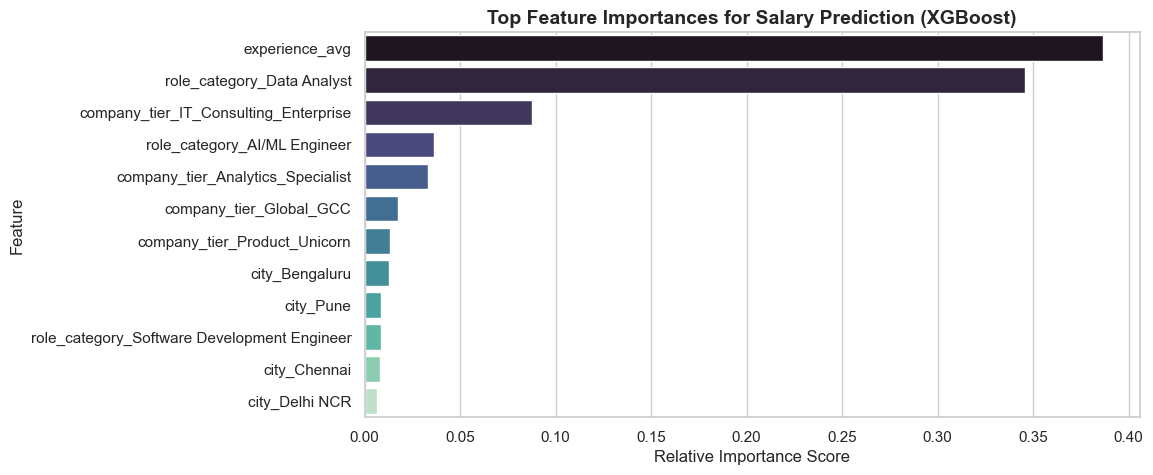

,Feature,Importance
0,experience_avg,0.386316
2,role_category_Data Analyst,0.345516
14,company_tier_IT_Consulting_Enterprise,0.087898
1,role_category_AI/ML Engineer,0.036149
12,company_tier_Analytics_Specialist,0.033361
13,company_tier_Global_GCC,0.017747
15,company_tier_Product_Unicorn,0.013100
5,city_Bengaluru,0.012934
10,city_Pune,0.008715
4,role_category_Software Development Engineer,0.008416


In [3]:
# Feature Importance from XGBoost Regressor
xgb_model = trained_pipelines["XGBoost Regressor"].named_steps["model"]
encoded_cat_names = trained_pipelines["XGBoost Regressor"].named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(categorical_cols)
all_feature_names = list(numerical_cols) + list(encoded_cat_names)

importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": xgb_model.feature_importances_
}).sort_values(by="Importance", ascending=False).head(12)

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x="Importance", y="Feature", palette="mako")
plt.title("Top Feature Importances for Salary Prediction (XGBoost)", fontsize=14, fontweight="bold")
plt.xlabel("Relative Importance Score")
plt.show()

importance_df


### 2. Model B — Job Role Classification (NLP + Classifier)

In [4]:
# Text & Role Classification
X_text = df["description_clean"] + " " + df["skills"]
y_role = df["role_category"]

X_tr_text, X_te_text, y_tr_role, y_te_role = train_test_split(X_text, y_role, test_size=0.2, random_state=42, stratify=y_role)

clf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=2500, ngram_range=(1, 2), stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

clf_pipeline.fit(X_tr_text, y_tr_role)
y_pred_role = clf_pipeline.predict(X_te_text)

acc = accuracy_score(y_te_role, y_pred_role)
print(f"Classification Accuracy: {acc * 100:.2f}%
")
print("--- Classification Report ---")
print(classification_report(y_te_role, y_pred_role))


  Cell In[4], line 16
    print(f"Classification Accuracy: {acc * 100:.2f}%
          ^
SyntaxError: unterminated f-string literal (detected at line 16)



In [5]:
# Confusion Matrix Heatmap
cm = confusion_matrix(y_te_role, y_pred_role, labels=clf_pipeline.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clf_pipeline.classes_, yticklabels=clf_pipeline.classes_)
plt.title("Confusion Matrix — Job Role Classification", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Role")
plt.ylabel("Actual Role")
plt.xticks(rotation=20)
plt.show()


---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
Cell In[5], line 2
      1 # Confusion Matrix Heatmap
----> 2 cm = confusion_matrix(y_te_role, y_pred_role, labels=clf_pipeline.classes_)
      3 plt.figure(figsize=(8, 6))
      4 sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clf_pipeline.classes_, yticklabels=clf_pipeline.classes_)

NameError: name 'y_te_role' is not defined


NameError: name 'y_te_role' is not defined